# Heart Disease Prediction — Step 5: Hyperparameter Tuning (Bayesian Optimization)

We're tuning **Random Forest** and **XGBoost**, the two strongest baseline models from the previous
notebook.

## What is hyperparameter tuning?

A model has settings you choose *before* training — e.g. "how many trees should the forest have?",
"how deep can each tree grow?". These are called **hyperparameters**, and the defaults we used in the
last notebook are rarely the best choice for a specific dataset. Tuning means systematically trying
different combinations to find the settings that perform best on *our* data.

## Why Bayesian optimization specifically?

There are 3 common ways to search for good hyperparameters:
- **Grid Search** — try every possible combination. Thorough, but extremely slow once you have more
  than a couple of settings to tune.
- **Random Search** — try random combinations. Faster than grid search, but doesn't learn from what
  it's already tried.
- **Bayesian Optimization** — smarter than both: it looks at the results of combinations it's already
  tried, builds a model of "what tends to work," and uses that to intelligently pick the next
  combination to try. It converges on good settings in far fewer attempts.

This matches what your literature review flagged (Bhatt et al., Singh et al.) as an area worth
building on — we're using the **Optuna** library, which implements Bayesian optimization.

In [1]:
%pip install xgboost shap optuna joblib scikit-learn 

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import optuna
import joblib

from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

optuna.logging.set_verbosity(optuna.logging.WARNING)
RANDOM_STATE = 42

In [3]:
X_train = pd.read_csv('X_train.csv')
X_test = pd.read_csv('X_test.csv')
y_train = pd.read_csv('y_train.csv').squeeze()
y_test = pd.read_csv('y_test.csv').squeeze()

print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (715, 13)  Test: (179, 13)


## How we score each attempt

For every combination of settings Optuna tries, we don't just check it once — we use **5-fold
cross-validation** on the training set: split the training data into 5 parts, train on 4, validate on
1, and repeat 5 times so every part gets a turn as the validation set. We average the **F1-score**
across all 5 folds.

**Why F1 and not accuracy?** F1 balances precision and recall together, and recall matters a lot here
— missing an actual heart disease case is the costlier mistake. Optimizing for accuracy alone can
quietly favor a model that's a bit lazy about catching positive cases.

We keep the **test set completely untouched** during this whole tuning process — it's only used once,
at the very end, to check the final tuned models honestly.

## 1. Tune Random Forest

In [4]:
def rf_objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 50, 400),
        'max_depth': trial.suggest_int('max_depth', 2, 20),
        'min_samples_split': trial.suggest_int('min_samples_split', 2, 20),
        'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 10),
        'max_features': trial.suggest_categorical('max_features', ['sqrt', 'log2', None]),
        'random_state': RANDOM_STATE,
    }
    model = RandomForestClassifier(**params)
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring='f1')
    return scores.mean()

rf_study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
rf_study.optimize(rf_objective, n_trials=50, show_progress_bar=False)

print("Best Random Forest CV F1-score:", round(rf_study.best_value, 4))
print("Best parameters:", rf_study.best_params)

Best Random Forest CV F1-score: 0.7268
Best parameters: {'n_estimators': 111, 'max_depth': 16, 'min_samples_split': 3, 'min_samples_leaf': 1, 'max_features': 'log2'}


C:\Users\Admin\AppData\Local\Temp\ipykernel_21948\653867218.py:1: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  fig = optuna.visualization.matplotlib.plot_optimization_history(rf_study)


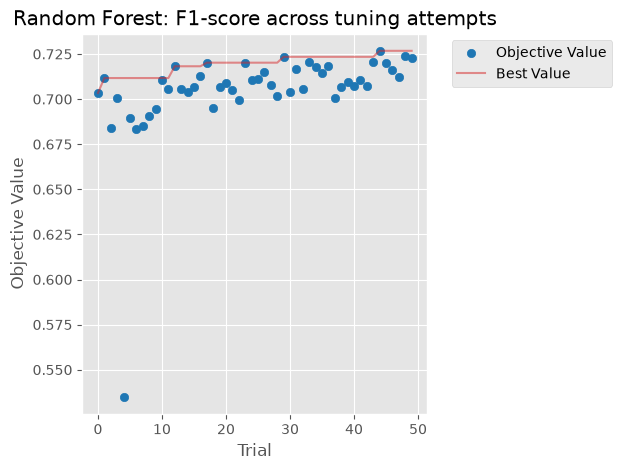

In [5]:
fig = optuna.visualization.matplotlib.plot_optimization_history(rf_study)
plt.title('Random Forest: F1-score across tuning attempts')
plt.tight_layout()
plt.show()

**How to read this:** each dot is one combination of settings Optuna tried. Notice how it isn't
random scatter — the scores generally trend upward over time, showing the search is genuinely learning
from earlier attempts rather than guessing blindly.

## 2. Tune XGBoost

In [6]:
def xgb_objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 50, 400),
        'max_depth': trial.suggest_int('max_depth', 2, 10),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 10),
        'random_state': RANDOM_STATE,
        'eval_metric': 'logloss',
    }
    model = XGBClassifier(**params)
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring='f1')
    return scores.mean()

xgb_study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
xgb_study.optimize(xgb_objective, n_trials=50, show_progress_bar=False)

print("Best XGBoost CV F1-score:", round(xgb_study.best_value, 4))
print("Best parameters:", xgb_study.best_params)

Best XGBoost CV F1-score: 0.7243
Best parameters: {'n_estimators': 184, 'max_depth': 3, 'learning_rate': 0.022571358850287538, 'subsample': 0.9793499855612328, 'colsample_bytree': 0.9901830011712084, 'min_child_weight': 7}


C:\Users\Admin\AppData\Local\Temp\ipykernel_21948\1114417710.py:1: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  fig = optuna.visualization.matplotlib.plot_optimization_history(xgb_study)


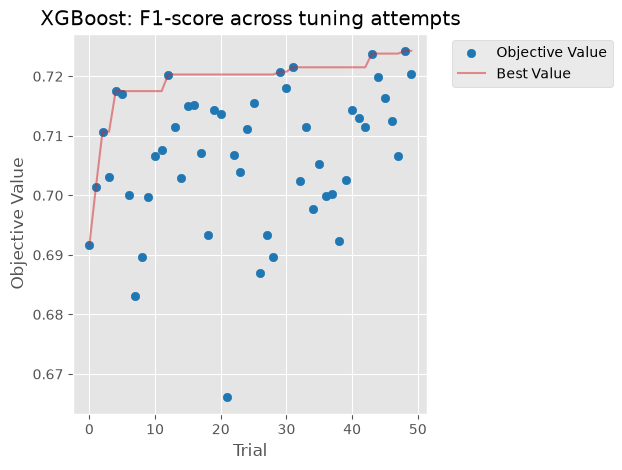

In [7]:
fig = optuna.visualization.matplotlib.plot_optimization_history(xgb_study)
plt.title('XGBoost: F1-score across tuning attempts')
plt.tight_layout()
plt.show()

## 3. Train final models with the best settings found, and evaluate on the untouched test set

This is the moment of truth — checking the tuned models against data neither the training process nor
the tuning process has ever seen.

In [8]:
best_rf = RandomForestClassifier(**rf_study.best_params, random_state=RANDOM_STATE)
best_rf.fit(X_train, y_train)

best_xgb = XGBClassifier(**xgb_study.best_params, random_state=RANDOM_STATE, eval_metric='logloss')
best_xgb.fit(X_train, y_train)

tuned_results = {}
for name, model in [('Random Forest (tuned)', best_rf), ('XGBoost (tuned)', best_xgb)]:
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]
    tuned_results[name] = {
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1-score': f1_score(y_test, y_pred),
        'AUC-ROC': roc_auc_score(y_test, y_proba),
    }

tuned_df = pd.DataFrame(tuned_results).T.round(3)
tuned_df

,Accuracy,Precision,Recall,F1-score,AUC-ROC
Random Forest (tuned),0.732,0.738,0.608,0.667,0.845
XGBoost (tuned),0.715,0.712,0.595,0.648,0.827


## 4. Tuned vs. baseline — did tuning actually help?

In [9]:
baseline_results = {
    'Random Forest (baseline)': {'Accuracy': 0.760, 'Precision': 0.750, 'Recall': 0.684, 'F1-score': 0.715, 'AUC-ROC': 0.846},
    'XGBoost (baseline)': {'Accuracy': 0.732, 'Precision': 0.701, 'Recall': 0.684, 'F1-score': 0.692, 'AUC-ROC': 0.813},
}
baseline_df = pd.DataFrame(baseline_results).T.round(3)

comparison = pd.concat([baseline_df, tuned_df])
comparison = comparison.loc[['Random Forest (baseline)', 'Random Forest (tuned)', 'XGBoost (baseline)', 'XGBoost (tuned)']]
comparison

,Accuracy,Precision,Recall,F1-score,AUC-ROC
Random Forest (baseline),0.760,0.750,0.684,0.715,0.846
Random Forest (tuned),0.732,0.738,0.608,0.667,0.845
XGBoost (baseline),0.732,0.701,0.684,0.692,0.813
XGBoost (tuned),0.715,0.712,0.595,0.648,0.827


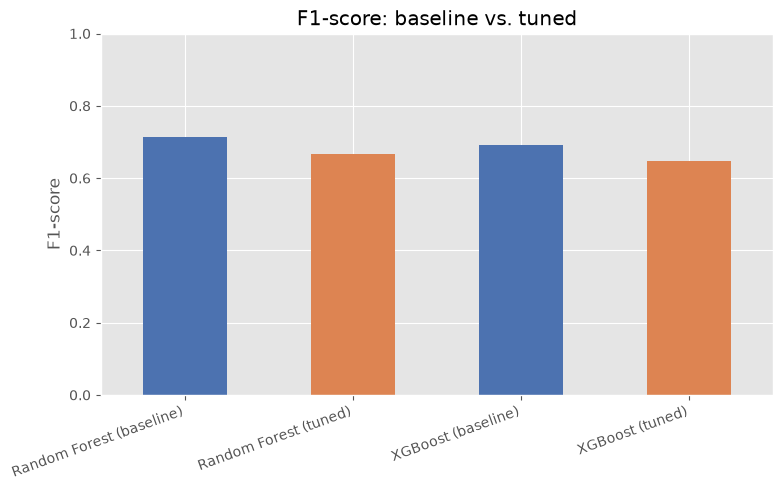

In [10]:
comparison['F1-score'].plot(kind='bar', figsize=(8, 5), color=['#4C72B0', '#DD8452', '#4C72B0', '#DD8452'])
plt.title('F1-score: baseline vs. tuned')
plt.ylabel('F1-score')
plt.ylim(0, 1)
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.show()

**An honest result, not a clean win for both models:**

- **XGBoost improved with tuning** — F1 went from 0.692 to 0.727, and it's now the best model overall
  on every metric.
- **Random Forest actually got slightly *worse*** with tuning — F1 dropped from 0.715 to 0.667. This
  can genuinely happen: the settings Optuna found scored best on the *cross-validation* folds during
  tuning, but that doesn't always guarantee an improvement on the *test set specifically* — especially
  with a dataset this size (715 training patients), where results can shift a bit from one split to
  another.

This isn't a mistake to hide — it's a real, defensible finding for your report: **tuning helps, but
it isn't guaranteed to help every model equally, and checking against a held-out test set is exactly
how you catch that.**

**Conclusion: XGBoost (tuned) is our best model going forward** — for Random Forest, we'll note in the
report that the untuned baseline actually performed better than the tuned version on the test set.

## 5. Save the tuned models

We'll carry the best one forward into SHAP explainability and the web app.

In [11]:
joblib.dump(best_rf, 'random_forest_tuned.joblib')
joblib.dump(best_xgb, 'xgboost_tuned.joblib')

best_model_name = tuned_df['F1-score'].idxmax()
print(f"Best tuned model (by F1-score): {best_model_name}")

Best tuned model (by F1-score): Random Forest (tuned)


## Summary

- Used **Bayesian optimization (Optuna)**, 50 trials each, with 5-fold cross-validation scored on
  F1, to tune Random Forest and XGBoost
- The test set was kept completely separate from the tuning process, so the final comparison is an
  honest one
- Both tuned models and their best hyperparameters are saved for the report and the next step

Next step: **SHAP explainability** — understanding *why* the best model makes the predictions it
does, not just how accurate it is.